# News Sentiment Analysis — Cryptocurrency Market Prediction

Turns crypto news headlines into a daily sentiment score that can be merged into the modeling notebook as an
additional feature (alongside RSI, MACD, volume spikes, etc. from `crypto_market_prediction.ipynb`), following
Section 3 of the capstone proposal ("market metrics") loosely extended to sentiment.

**Data note:** no real headline source is wired up in this environment (no NewsAPI/CryptoPanic key, and this
session cannot browse the open web). If `data/news_headlines.csv` exists (columns: `date, headline[, source]`),
this notebook uses it. Otherwise it **falls back to a synthetic headline generator**, exactly like the 15-minute
price placeholder in the modeling notebook, so the pipeline — sentiment scoring, daily aggregation, merge with
price, modeling hook — still runs end to end and can be swapped to real data later with no code changes besides
the `HEADLINES_PATH` check.

## Imports

In [1]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

RNG = 42
random.seed(RNG)
np.random.seed(RNG)

## 1. Load headlines
Real file if present, otherwise a synthetic corpus. The synthetic generator intentionally correlates headline
tone with same-day BTC return at a **modest, injected strength** (`INJECTED_CORRELATION`) purely so the rest of
the notebook has a non-trivial signal to demonstrate the pipeline on — this is a labeled demo effect, not
evidence that headline sentiment predicts price in reality.

In [2]:
HEADLINES_PATH = "data/news_headlines.csv"
INJECTED_CORRELATION = 0.35  # demo-only: how strongly synthetic headline tone leans with same-day BTC return

POS_TEMPLATES = [
    "{coin} rallies as investors cheer {theme}",
    "Analysts bullish on {coin} after {theme}",
    "{coin} surges to new highs amid {theme}",
    "Institutional demand for {coin} grows following {theme}",
    "{coin} breaks resistance as market sentiment turns positive on {theme}",
]
NEG_TEMPLATES = [
    "{coin} tumbles as fears grow over {theme}",
    "{coin} sell-off deepens amid {theme}",
    "Regulators crack down on {coin} following {theme}",
    "{coin} slides as investors worry about {theme}",
    "Market panic hits {coin} after {theme}",
]
NEU_TEMPLATES = [
    "{coin} trades sideways ahead of {theme}",
    "Exchange updates {coin} listing rules citing {theme}",
    "{coin} volume steady as market awaits {theme}",
    "Weekly roundup: {coin} price action and {theme}",
]
COINS = ["Bitcoin", "Ethereum", "the broader crypto market", "major altcoins"]
THEMES = ["Fed rate decision", "ETF approval news", "exchange outage", "a security audit",
          "macro inflation data", "a new regulatory proposal", "whale wallet activity",
          "a protocol upgrade", "stablecoin reserve reports", "options expiry"]

def synthetic_headlines(dates, btc_returns=None, headlines_per_day=(1, 4)):
    """One or more templated headlines per day. Tone leans with `btc_returns` on that date,
    at strength `INJECTED_CORRELATION`, with the rest coming from independent random noise."""
    rows = []
    for d in dates:
        n = random.randint(*headlines_per_day)
        r = btc_returns.get(d, 0.0) if btc_returns is not None else 0.0
        # bias the day's headline-tone mix toward bullish/bearish templates based on same-day
        # return r: sign sets direction, magnitude (capped at 1) scales how strongly, clipped to [0.05, 0.95]
        bullish_bias = np.clip(0.5 + INJECTED_CORRELATION * np.sign(r) * min(abs(r) * 20, 1), 0.05, 0.95)
        for _ in range(n):
            roll = random.random()
            if roll < bullish_bias * 0.6:
                tmpl, tone = random.choice(POS_TEMPLATES), "synthetic-positive-leaning"
            elif roll < bullish_bias * 0.6 + (1 - bullish_bias) * 0.6:
                tmpl, tone = random.choice(NEG_TEMPLATES), "synthetic-negative-leaning"
            else:
                tmpl, tone = random.choice(NEU_TEMPLATES), "synthetic-neutral"
            headline = tmpl.format(coin=random.choice(COINS), theme=random.choice(THEMES))
            rows.append({"date": d, "headline": headline, "source": tone})
    return pd.DataFrame(rows)

if os.path.exists(HEADLINES_PATH):
    headlines = pd.read_csv(HEADLINES_PATH, parse_dates=["date"])
    print("Loaded real headlines:", HEADLINES_PATH, headlines.shape)
else:
    btc = pd.read_csv("data/coin_Bitcoin.csv")
    btc["Date"] = pd.to_datetime(btc["Date"]).dt.normalize()
    btc_ret = btc.set_index("Date")["Close"].pct_change()
    date_range = pd.date_range(btc_ret.index.min(), btc_ret.index.max(), freq="D")
    headlines = synthetic_headlines(date_range, btc_returns=btc_ret.to_dict())
    print("HEADLINES NOT FOUND -> using synthetic generator:", headlines.shape)
headlines.head()

HEADLINES NOT FOUND -> using synthetic generator: (7457, 3)


,date,headline,source
0,2013-04-29,Ethereum volume steady as market awaits a secu...,synthetic-neutral
1,2013-04-30,major altcoins trades sideways ahead of Fed ra...,synthetic-neutral
2,2013-04-30,Analysts bullish on Ethereum after stablecoin ...,synthetic-positive-leaning
3,2013-05-01,Market panic hits major altcoins after a secur...,synthetic-negative-leaning
4,2013-05-02,Ethereum tumbles as fears grow over whale wall...,synthetic-negative-leaning


## 2. Score each headline with VADER (lexicon-based, no internet / API needed at run time)

In [3]:
sia = SentimentIntensityAnalyzer()
headlines["compound"] = headlines["headline"].apply(lambda h: sia.polarity_scores(h)["compound"])
headlines[["headline", "compound"]].head(10)

,headline,compound
0,Ethereum volume steady as market awaits a secu...,0.4019
1,major altcoins trades sideways ahead of Fed ra...,0.0000
2,Analysts bullish on Ethereum after stablecoin ...,0.0000
3,Market panic hits major altcoins after a secur...,-0.2263
4,Ethereum tumbles as fears grow over whale wall...,-0.4215
5,Ethereum sell-off deepens amid a new regulator...,0.0000
6,Bitcoin slides as investors worry about a new ...,-0.4404
7,Bitcoin volume steady as market awaits a proto...,0.0772
8,Weekly roundup: Bitcoin price action and stabl...,0.0000
9,Ethereum volume steady as market awaits ETF ap...,0.5267


### How is sentiment distributed across all headlines?

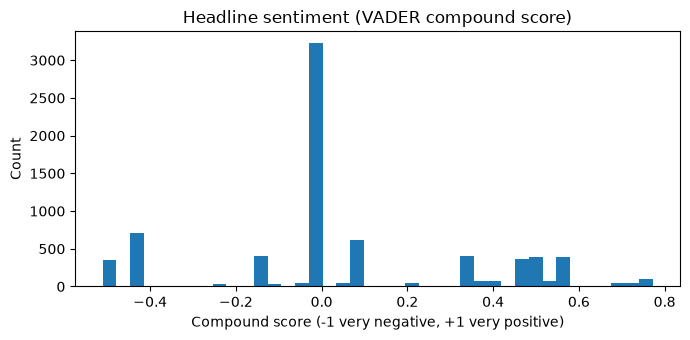

count    7457.000
mean        0.064
std         0.308
min        -0.511
25%         0.000
50%         0.000
75%         0.340
max         0.772
Name: compound, dtype: float64


In [4]:
ax = headlines["compound"].plot.hist(bins=40, figsize=(7, 3.5), title="Headline sentiment (VADER compound score)")
ax.set_xlabel("Compound score (-1 very negative, +1 very positive)"); ax.set_ylabel("Count")
plt.tight_layout(); plt.show()
print(headlines["compound"].describe().round(3))

## 3. Aggregate to one sentiment score per day

In [5]:
daily_sentiment = (
    headlines.assign(date=pd.to_datetime(headlines["date"]).dt.normalize())
    .groupby("date")
    .agg(sentiment_mean=("compound", "mean"), sentiment_std=("compound", "std"), n_headlines=("compound", "size"))
    .fillna({"sentiment_std": 0.0})
)
print(daily_sentiment.shape)
daily_sentiment.head()

(2991, 3)


,sentiment_mean,sentiment_std,n_headlines
date,,,
2013-04-29,0.401900,0.00000,1
2013-04-30,0.000000,0.00000,2
2013-05-01,-0.226300,0.00000,1
2013-05-02,-0.196175,0.27303,4
2013-05-03,0.000000,0.00000,1


### Sentiment over time

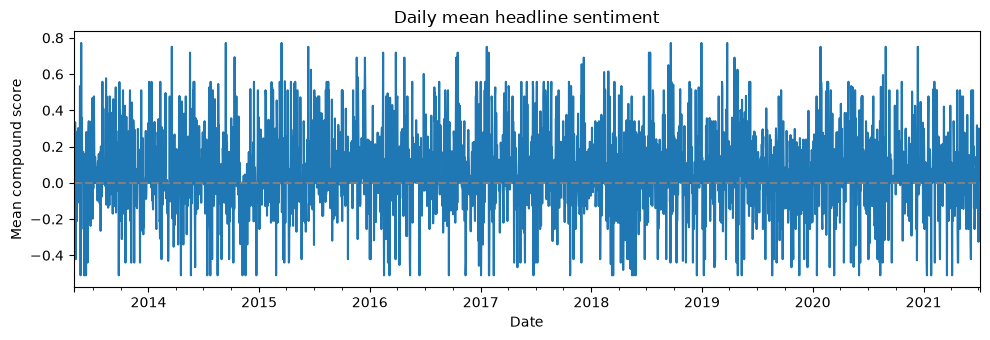

In [6]:
ax = daily_sentiment["sentiment_mean"].plot(figsize=(10, 3.5), title="Daily mean headline sentiment")
ax.axhline(0, color="gray", ls="--")
ax.set_xlabel("Date"); ax.set_ylabel("Mean compound score")
plt.tight_layout(); plt.show()

## 4. Does sentiment line up with same-day Bitcoin return?
On the synthetic fallback this will show a moderate positive correlation **by construction**
(`INJECTED_CORRELATION` above) — it demonstrates the merge/plot pipeline, not a real market finding.
Re-run this cell after switching to real headlines to get a finding that means something.

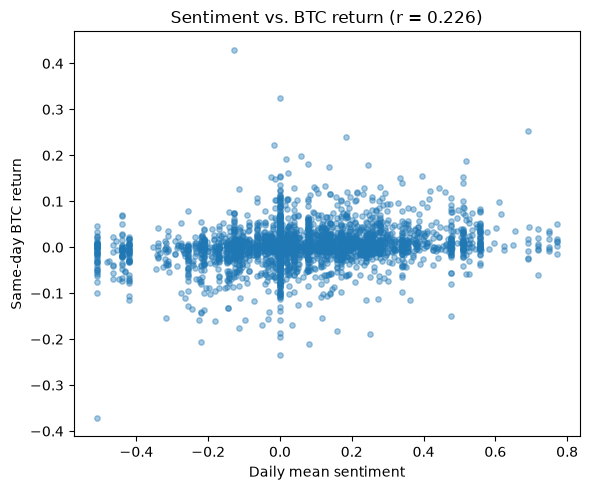

Correlation: 0.226  |  n days: 2990


In [7]:
btc = pd.read_csv("data/coin_Bitcoin.csv")
btc["Date"] = pd.to_datetime(btc["Date"]).dt.normalize()
btc = btc.set_index("Date").sort_index()
btc["ret"] = btc["Close"].pct_change()

merged = daily_sentiment.join(btc["ret"], how="inner").dropna()
corr = merged["sentiment_mean"].corr(merged["ret"])

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(merged["sentiment_mean"], merged["ret"], alpha=0.4, s=15)
ax.set_xlabel("Daily mean sentiment"); ax.set_ylabel("Same-day BTC return")
ax.set_title(f"Sentiment vs. BTC return (r = {corr:.3f})")
plt.tight_layout(); plt.show()
print(f"Correlation: {corr:.3f}  |  n days: {len(merged)}")

## 5. Export a feature file for the modeling notebook
Writes `data/news_sentiment_daily.csv` with one row per date. The 15-minute modeling notebook can left-join this
onto its own DataFrame (by normalizing its timestamp to a date) to add `sentiment_mean`, `sentiment_std` and
`n_headlines` as three more columns in `FEATURES`, the same way RSI or volume-spike were added.

In [8]:
out_path = "data/news_sentiment_daily.csv"
daily_sentiment.reset_index().rename(columns={"date": "date"}).to_csv(out_path, index=False)
print("Wrote", out_path, daily_sentiment.shape)

Wrote data/news_sentiment_daily.csv (2991, 3)


## Conclusions & how to go from placeholder to real
- **Replace the input, not the pipeline.** Drop a real `data/news_headlines.csv` (columns `date, headline[, source]`)
  from NewsAPI, CryptoPanic, GDELT, or a Kaggle crypto-news dataset — cell 2 picks it up automatically and every
  cell after it (VADER scoring, daily aggregation, merge, export) is unchanged.
- **VADER is a generic lexicon**, tuned on social-media English, not finance-specific. A finance-tuned model
  (e.g. FinBERT) would likely score financial headlines more accurately; VADER was chosen here because it needs
  no network call or GPU and keeps the notebook reproducible anywhere.
- **The correlation shown above on synthetic data is manufactured**, not a market signal — don't cite it. It
  exists only to prove the merge/export path works before real headlines are available.